# BAN 8101 Predictive Analytics
## Week 8: Neural Network Foundations for Autonomous Driving

### Big Question
**How can a neural network learn a nonlinear relationship between driving conditions and steering behavior?**

This week begins the neural-network portion of the course. We will first use **structured driving-state variables** rather than raw images so we can focus on how neural networks learn.

Later, the same ideas will be extended to road images and CNN-based steering prediction.

### Learning Objectives
After this module, you should be able to:
- Explain inputs, weights, biases, hidden layers, and outputs
- Compute the output of a simple neuron
- Explain activation functions and nonlinearity
- Describe forward propagation
- Explain loss, gradient descent, and backpropagation
- Build and train a neural network in PyTorch
- Interpret training and validation loss
- Compare simple and larger neural-network architectures
- Connect neural-network training to the final self-driving simulation project

## Asynchronous Week — How to Use This Notebook

This week is designed to be completed **asynchronously**. There is no lecture recording required.

**Estimated completion time: 90–120 minutes.**

Please work through the notebook **in order**:

1. Read each Markdown explanation before running the code below it.
2. Run one code cell at a time rather than using **Run All** immediately.
3. Pause at the **What to Notice**, **Pause and Think**, and **Check Your Understanding** sections.
4. Focus on understanding the process, not memorizing PyTorch syntax.
5. If your output looks different from what you expected, read the surrounding explanation before changing the code.

The most important idea this week is the complete training cycle:

$$
\text{Input}
\rightarrow
\text{Forward Pass}
\rightarrow
\text{Prediction}
\rightarrow
\text{Loss}
\rightarrow
\text{Backpropagation}
\rightarrow
\text{Weight Update}
$$

You will use this same learning process later with road images and CNN-based steering prediction.

# 1. From Logistic Regression to Neural Networks

A familiar model starts with a weighted sum:

$$
z=w_1x_1+w_2x_2+\cdots+w_px_p+b
$$

A neural network extends this idea by arranging many neurons into layers:

$$
\text{Inputs}\rightarrow\text{Hidden Layer}\rightarrow\text{Hidden Layer}\rightarrow\text{Output}
$$

The hidden layers allow the model to learn more complicated nonlinear relationships.

# 2. A Single Artificial Neuron

For one neuron:

$$
z=\sum_{j=1}^{p}w_jx_j+b
$$

Then:

$$
a=f(z)
$$

where $x_j$ is an input(data), $w_j$ is a weight(coefficient), $b$ is a bias, and $f$ is an activation function.

In [1]:
import numpy as np

# MANUAL NEURON EXAMPLE
# Three simplified driving inputs:
# road curvature, lateral offset, and heading error.
x = np.array([
    0.60,   # road curvature: positive = right curve
   -0.20,   # lateral offset: negative = left of lane center
    5.00    # heading error in degrees
])

# Example weights and bias.
# During real training, these values are LEARNED from data.
w = np.array([1.20, -0.80, 0.05])
b = -0.10

# Weighted sum: z = w1*x1 + w2*x2 + w3*x3 + b
z = np.dot(w, x) + b
print("Weighted sum z =", round(z, 3))

# BUSINESS INTERPRETATION:
# A positive or negative value of z does not yet mean "turn right" or
# "turn left" by itself. It is simply the neuron's weighted combination
# of the inputs before an activation function is applied.


Weighted sum z = 1.03


### What to Notice

The neuron calculation has two parts:

1. multiply each input by a weight,
2. add the bias.

A weight can be positive or negative. A larger absolute weight means that input has a stronger influence on the neuron's intermediate result.

The bias shifts the result before the activation function is applied.

At this stage, **nothing has been learned yet**. We manually selected the weights only to understand the calculation.

# 3. Activation Functions

Without nonlinear activation functions, stacking many layers would still behave like one large linear transformation.

A common hidden-layer activation is ReLU:

$$
ReLU(z)=\max(0,z)
$$

Other common activations include sigmoid and tanh.

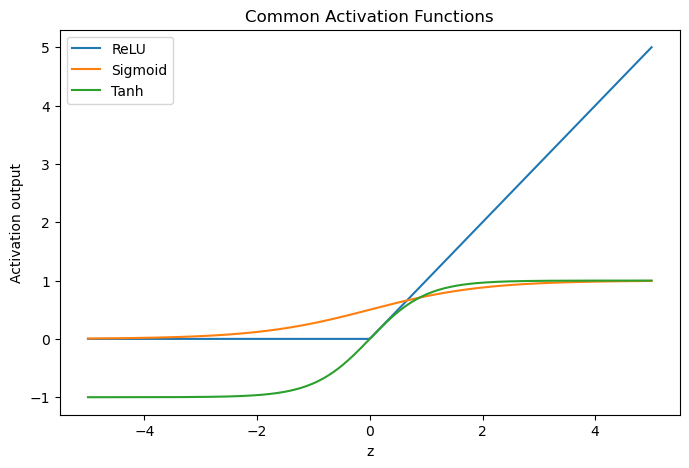

In [2]:
import matplotlib.pyplot as plt

# Create a range of z values so we can compare activations visually.
z_values = np.linspace(-5, 5, 300)
relu = np.maximum(0, z_values)
sigmoid = 1 / (1 + np.exp(-z_values))
tanh = np.tanh(z_values)

plt.figure(figsize=(8,5))
plt.plot(z_values, relu, label="ReLU")
plt.plot(z_values, sigmoid, label="Sigmoid")
plt.plot(z_values, tanh, label="Tanh")
plt.xlabel("z")
plt.ylabel("Activation output")
plt.title("Common Activation Functions")
plt.legend()
plt.show()

### Check Your Understanding

- **ReLU** is commonly used in hidden layers because it is simple and introduces nonlinearity.
- **Sigmoid** maps values between 0 and 1.
- **Tanh** maps values between -1 and 1.

For this course, the key idea is not memorizing every formula. It is understanding that activation functions allow the network to represent relationships that are more complex than one straight-line equation.

## Pause and Think

Why does a neural network need nonlinear activation functions?

Because the relationship between road conditions and steering behavior is rarely perfectly linear. Nonlinearity gives the network the flexibility to learn more complex behavior.

# 4. Our Week 8 Driving Problem

We will build a neural network that predicts:

- Left
- Straight
- Right

from five driving-state inputs:

1. road curvature
2. lateral offset
3. heading error
4. speed
5. obstacle distance

Architecture:

$$
5\ Inputs\rightarrow16\rightarrow8\rightarrow3\ Outputs
$$

This is a simplified stepping stone toward the final simulator project.

# 5. Create a Reproducible Driving-State Dataset

In [3]:
import pandas as pd

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
n = 5000

# Generate simplified vehicle-state variables.
road_curvature = rng.uniform(-1.0, 1.0, n)
lateral_offset = np.clip(rng.normal(0, 0.35, n), -1.2, 1.2)
heading_error = np.clip(rng.normal(0, 6.0, n), -20, 20)
speed = rng.uniform(5, 25, n)
obstacle_distance = rng.uniform(5, 100, n)

# Create a synthetic steering score.
# The nonlinear terms give the network something meaningful to learn.
steering_score = (
    0.95 * road_curvature
    - 0.55 * lateral_offset
    - 0.025 * heading_error
    + 0.30 * (road_curvature ** 3)
    + 0.012 * speed * road_curvature
    + rng.normal(0, 0.12, n)
)

LEFT_THRESHOLD = -0.12
RIGHT_THRESHOLD = 0.12

steering_class = np.where(
    steering_score < LEFT_THRESHOLD,
    "Left",
    np.where(steering_score > RIGHT_THRESHOLD, "Right", "Straight")
)

driving = pd.DataFrame({
    "road_curvature": road_curvature,
    "lateral_offset": lateral_offset,
    "heading_error": heading_error,
    "speed": speed,
    "obstacle_distance": obstacle_distance,
    "steering_class": steering_class
})

driving.head()

# WHAT TO NOTICE:
# We intentionally include both linear and nonlinear relationships.
# This gives the neural network an opportunity to learn patterns that
# a simple linear model may not capture as well.


,road_curvature,lateral_offset,heading_error,speed,obstacle_distance,steering_class
0,0.547912,-0.384624,9.048463,7.403248,45.285019,Right
1,-0.122243,-0.189460,12.346813,20.083335,50.797579,Left
2,0.717196,0.095200,1.407543,8.072793,92.571925,Right
3,0.394736,-0.219912,-3.830575,22.336479,34.989267,Right
4,-0.811645,-0.097428,-1.329839,9.811139,21.023505,Left


### What to Notice

Each row represents a **driving state**, not an entire trip.

The neural network will try to learn a mapping such as:

$$
\text{Driving Conditions}
\rightarrow
\text{Steering Behavior}
$$

This resembles the final project conceptually, even though the final project will use richer inputs such as camera images and simulator state.

In [4]:
# Inspect class balance before modeling.
display(pd.DataFrame({
    "Count": driving["steering_class"].value_counts(),
    "Proportion": driving["steering_class"].value_counts(normalize=True).round(3)
}))

,Count,Proportion
steering_class,,
Left,2279,0.456
Right,2201,0.440
Straight,520,0.104


# 6. Prepare the Data

Neural networks usually train more effectively when predictors are on similar scales.

We standardize using:

$$
z=\frac{x-\mu}{\sigma}
$$

The scaler must be fit on **training data only** to prevent leakage.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

feature_names = [
    "road_curvature",
    "lateral_offset",
    "heading_error",
    "speed",
    "obstacle_distance"
]

X = driving[feature_names].to_numpy(dtype=np.float32)
y_text = driving["steering_class"].to_numpy()

# PyTorch classification targets are integer class IDs.
class_to_id = {"Left":0, "Straight":1, "Right":2}
id_to_class = {v:k for k,v in class_to_id.items()}
y = np.array([class_to_id[label] for label in y_text], dtype=np.int64)

# Hold out 20% as a final test set.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Split development data into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=RANDOM_STATE, stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# WHY THREE DATASETS?
# Training set   -> used to update neural-network weights
# Validation set -> used to monitor generalization during development
# Test set       -> kept untouched until final evaluation
#
# This is the same principle used earlier in the course, but it is
# especially important for neural networks because they can overfit.


Training: (3200, 5)
Validation: (800, 5)
Test: (1000, 5)


### Why Training, Validation, and Test Sets Are Different

Think of the three datasets as having different jobs:

- **Training set:** teaches the network.
- **Validation set:** helps us judge whether training decisions generalize.
- **Test set:** provides a final check after development is complete.

Using the test set repeatedly while tuning the model would make the final result overly optimistic.

In [6]:
# Standardize predictors.
# fit_transform() is used ONLY on training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Training means:", np.round(X_train_scaled.mean(axis=0), 3))
print("Training standard deviations:", np.round(X_train_scaled.std(axis=0), 3))

# BUSINESS INTERPRETATION:
# Scaling does NOT change the meaning of the variables.
# It only places them on comparable numerical scales so one large-unit
# variable, such as obstacle distance, does not dominate optimization.


Training means: [0. 0. 0. 0. 0.]
Training standard deviations: [1. 1. 1. 1. 1.]


# 7. Convert NumPy Arrays to PyTorch Tensors

PyTorch uses **tensors**. They are similar to NumPy arrays but support automatic differentiation and GPU operations.

In [7]:
import torch
import torch.nn as nn

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("X_train tensor:", X_train_t.shape)
print("y_train tensor:", y_train_t.shape)

# WHAT TO NOTICE:
# The values have not changed conceptually. We are only changing the
# data structure from NumPy arrays to PyTorch tensors so PyTorch can
# track gradients and train the network.


X_train tensor: torch.Size([3200, 5])
y_train tensor: torch.Size([3200])


### What Is a Tensor?

For this course, you can think of a PyTorch tensor as a NumPy array with extra capabilities for neural-network training.

The important feature is **automatic differentiation**: PyTorch can keep track of the mathematical operations performed during the forward pass and then calculate gradients during backpropagation.

# 8. Define Our First Neural Network

We will use:

$$
5\rightarrow16\rightarrow8\rightarrow3
$$

The final layer produces three raw class scores called **logits**.

In [8]:
class SteeringNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(5, 16),   # 5 inputs -> 16 hidden neurons
            nn.ReLU(),          # nonlinearity
            nn.Linear(16, 8),   # 16 -> 8 hidden neurons
            nn.ReLU(),
            nn.Linear(8, 3)     # 3 output logits
        )

    def forward(self, x):
        # This method defines forward propagation.
        return self.network(x)

model = SteeringNet()
print(model)

# HOW TO READ THIS MODEL:
# nn.Linear(5, 16) means 5 input values are connected to 16 neurons.
# nn.ReLU() applies a nonlinear transformation.
# nn.Linear(16, 8) passes the 16 hidden values to 8 more neurons.
# nn.Linear(8, 3) creates three final scores: Left, Straight, Right.


SteeringNet(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


### How to Read the Architecture

The first number in each `Linear` layer is the number of values entering the layer. The second is the number leaving it.

For example:

```python
nn.Linear(5, 16)
```

means:

> take 5 input variables and calculate 16 new hidden values.

The hidden values are not business variables with obvious names. They are learned internal representations created by the network.

# 9. Logits, Softmax, and Probabilities

The final network output might be:

```text
[-0.8, 0.3, 1.5]
```

These are logits, not probabilities.

Softmax converts logits into probabilities:

$$
P(y=k)=\frac{e^{z_k}}{\sum_j e^{z_j}}
$$

For training, PyTorch's `CrossEntropyLoss` expects raw logits, so we do **not** apply softmax before the loss function.

In [9]:
# Run a forward pass BEFORE training.
# Predictions are not meaningful yet because the weights are random.
with torch.no_grad():
    sample_logits = model(X_train_t[:3])

print("Raw logits:")
print(sample_logits)
print("\nProbabilities:")
print(torch.softmax(sample_logits, dim=1))

# WHAT TO NOTICE:
# Before training, the output probabilities are largely arbitrary
# because the model has not yet learned useful weights from the data.


Raw logits:
tensor([[ 0.0516,  0.3894,  0.0262],
        [ 0.0363,  0.3833,  0.0842],
        [-0.0481,  0.4258, -0.0679]])

Probabilities:
tensor([[0.2961, 0.4152, 0.2887],
        [0.2887, 0.4084, 0.3029],
        [0.2788, 0.4479, 0.2733]])


### Logits vs. Probabilities

This distinction is important:

- **Logits** are the raw output scores from the last layer.
- **Softmax probabilities** convert those scores into values that sum to 1.
- **CrossEntropyLoss** expects logits directly.

So during training, do not apply softmax before `CrossEntropyLoss`.

# 10. Loss, Gradient Descent, and Backpropagation

The training cycle is:

$$
\text{Forward Pass}
\rightarrow
\text{Prediction}
\rightarrow
\text{Loss}
\rightarrow
\text{Backpropagation}
\rightarrow
\text{Weight Update}
$$

Gradient descent updates weights approximately as:

$$
w_{new}=w_{old}-\eta\frac{\partial L}{\partial w}
$$

Backpropagation efficiently computes the gradients through the network.

# 11. Configure the Training Process

In [10]:
torch.manual_seed(RANDOM_STATE)
model = SteeringNet()

# CrossEntropyLoss is appropriate for 3-class classification.
criterion = nn.CrossEntropyLoss()

# Adam uses the gradients to update the network parameters.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

EPOCHS = 120

# WHY THESE TWO OBJECTS MATTER:
# criterion = tells the model how wrong its predictions are
# optimizer = tells the model how to adjust weights to reduce that error
#
# They work together during every training epoch.


### Training Vocabulary

**Epoch:** one complete training pass through the training data.

**Learning rate:** controls how large each parameter update is.

**Optimizer:** applies the parameter updates using the gradients.

A learning rate that is too large can cause unstable training. A very small learning rate may make learning unnecessarily slow.

# 12. The Training Loop

For each epoch:

1. clear previous gradients
2. perform a forward pass
3. calculate loss
4. backpropagate
5. update weights
6. calculate validation loss

In [11]:
train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    # ---------- TRAINING ----------
    model.train()

    # PyTorch accumulates gradients by default, so clear old ones.
    optimizer.zero_grad()

    # Forward pass: produce logits for all training observations.
    train_logits = model(X_train_t)

    # Compare predictions with the correct classes.
    train_loss = criterion(train_logits, y_train_t)

    # Backpropagation: calculate gradients.
    train_loss.backward()

    # Weight update: optimizer uses the gradients.
    optimizer.step()

    train_losses.append(train_loss.item())

    # ---------- VALIDATION ----------
    model.eval()

    # Validation should not update weights.
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    val_losses.append(val_loss.item())

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

# KEY IDEA:
# One epoch means the model has used the training data once to update
# its parameters. Repeating many epochs gives the network multiple
# opportunities to improve, but too many can lead to overfitting.


Epoch  20 | Train Loss: 0.6773 | Validation Loss: 0.6503
Epoch  40 | Train Loss: 0.2997 | Validation Loss: 0.3096
Epoch  60 | Train Loss: 0.2288 | Validation Loss: 0.2434
Epoch  80 | Train Loss: 0.1823 | Validation Loss: 0.2137
Epoch 100 | Train Loss: 0.1718 | Validation Loss: 0.2135
Epoch 120 | Train Loss: 0.1694 | Validation Loss: 0.2140


### What the Training Loop Is Actually Doing

The loop may look technical, but conceptually it repeats the same business-analytics workflow:

1. make predictions,
2. measure how wrong they are,
3. identify how the model should change,
4. update the model,
5. check whether performance improves.

Backpropagation is the mechanism that makes Step 3 efficient for a network with many weights.

# 13. Training and Validation Loss

Training loss tells us how well the network fits the training data.

Validation loss helps us judge generalization.

Possible overfitting:

> training loss keeps decreasing while validation loss begins increasing.

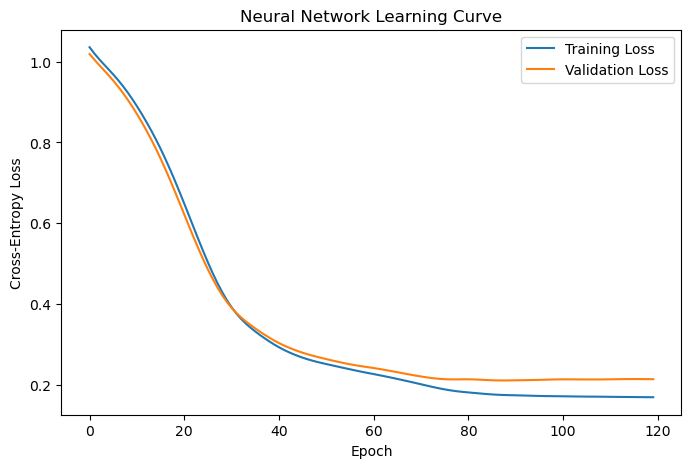

In [12]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Neural Network Learning Curve")
plt.legend()
plt.show()

### What to Notice in the Learning Curves

Do not judge the model only by whether training loss decreases.

The important comparison is between **training loss** and **validation loss**.

- Both decreasing: learning is generally improving.
- Training decreasing while validation worsens: possible overfitting.
- Both remaining high: possible underfitting or training problems.

This is the neural-network version of the model-complexity problem studied earlier in the course.

## Pause and Think

- Did both losses decrease?
- Did the curves separate?
- Would more epochs necessarily improve the model?
- How does this connect to overfitting in Decision Trees?

# 14. Convert Outputs into Steering Predictions

In [13]:
model.eval()

with torch.no_grad():
    val_logits = model(X_val_t)
    # argmax selects the class with the largest logit.
    val_pred_t = torch.argmax(val_logits, dim=1)

val_pred = val_pred_t.numpy()

print("Validation Accuracy:", round(accuracy_score(y_val, val_pred), 3))
print("Validation Macro F1:", round(f1_score(y_val, val_pred, average="macro"), 3))

# WHY argmax?
# The network outputs one score for each class.
# argmax chooses the position of the largest score:
#   0 -> Left
#   1 -> Straight
#   2 -> Right


Validation Accuracy: 0.902
Validation Macro F1: 0.816


### Check Your Understanding

Accuracy answers:

> What proportion of all observations were classified correctly?

Macro F1 gives equal importance to Left, Straight, and Right.

For a steering model, Macro F1 is useful because a model should not receive a strong score simply by performing well on the most common steering class.

# 15. Confusion Matrix

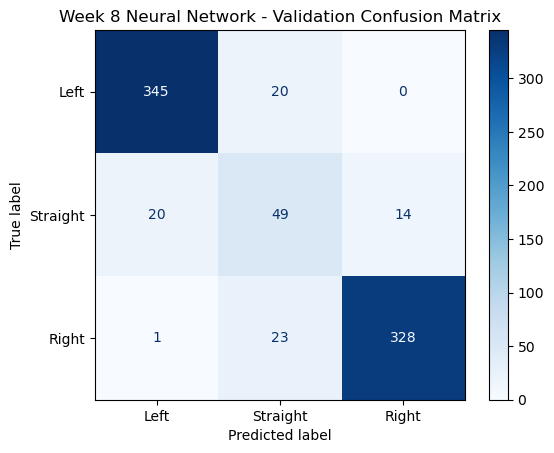

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    display_labels=["Left","Straight","Right"],
    cmap="Blues"
)
plt.title("Week 8 Neural Network - Validation Confusion Matrix")
plt.show()

# BUSINESS / SAFETY INTERPRETATION:
# Do not look only at the diagonal. Pay attention to the type of errors.
# In autonomous driving, confusing Left with Right may be much more
# serious than confusing a weak turn with Straight.


# 16. Prediction Confidence

Probability estimates help us distinguish confident and uncertain predictions.

In autonomous driving, uncertainty may eventually influence whether a controller proceeds normally, slows down, or uses a fallback strategy.

In [15]:
with torch.no_grad():
    # Convert validation logits to class probabilities.
    val_prob = torch.softmax(val_logits, dim=1)

# Highest class probability becomes a simple confidence measure.
val_confidence = torch.max(val_prob, dim=1).values.numpy()

confidence_table = pd.DataFrame({
    "Actual": [id_to_class[i] for i in y_val[:10]],
    "Predicted": [id_to_class[i] for i in val_pred[:10]],
    "Confidence": np.round(val_confidence[:10], 3)
})

confidence_table

# IMPORTANT:
# This is a simple confidence measure based on the highest predicted
# probability. High confidence does not guarantee correctness.
# It only tells us how strongly the model preferred one class.


,Actual,Predicted,Confidence
0,Right,Right,0.866
1,Left,Left,1.000
2,Left,Left,1.000
3,Left,Left,0.998
4,Left,Left,0.960
5,Left,Left,0.999
6,Left,Left,1.000
7,Left,Left,1.000
8,Right,Right,0.910
9,Right,Right,0.964


### Why Confidence Matters for the Final Project

A prediction can be correct but uncertain, or wrong but highly confident.

In a future autonomous-driving system, low confidence could potentially trigger a safer response such as:

- slowing down,
- requesting another observation,
- using another controller,
- or applying a fallback rule.

We are not implementing those behaviors yet, but this is the beginning of **safety-aware model evaluation**.

# 17. Compare with Logistic Regression

A neural network is not automatically better because it is more advanced.

A more complex model should earn its complexity through better performance or more useful behavior.

In [16]:
from sklearn.linear_model import LogisticRegression

baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)
baseline_pred = baseline.predict(X_val_scaled)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Neural Network"],
    "Validation Accuracy": [
        accuracy_score(y_val, baseline_pred),
        accuracy_score(y_val, val_pred)
    ],
    "Validation Macro F1": [
        f1_score(y_val, baseline_pred, average="macro"),
        f1_score(y_val, val_pred, average="macro")
    ]
})

comparison.round(3)

# WHY KEEP A BASELINE?
# A neural network should not be preferred merely because it is more
# sophisticated. If Logistic Regression performs nearly as well, the
# simpler model may still be attractive because it is easier to explain.


,Model,Validation Accuracy,Validation Macro F1
0,Logistic Regression,0.911,0.824
1,Neural Network,0.902,0.816


### Pause and Think

If Logistic Regression and the neural network have nearly identical validation performance, should you automatically choose the neural network?

Not necessarily.

A more complex model should provide enough benefit to justify its additional training, tuning, maintenance, and interpretability costs.

# 18. Does a Larger Network Automatically Perform Better?

Compare:

$$
5\rightarrow16\rightarrow8\rightarrow3
$$

with:

$$
5\rightarrow64\rightarrow32\rightarrow16\rightarrow3
$$

A larger network has more parameters and more flexibility—but also more opportunity to overfit.

In [17]:
class LargerSteeringNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)


def train_network(model, epochs=120, learning_rate=0.01):
    """Train one network and return training/validation loss histories."""

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_history = []
    val_history = []

    for epoch in range(epochs):
        # Training
        model.train()
        optimizer.zero_grad()
        train_logits = model(X_train_t)
        train_loss = criterion(train_logits, y_train_t)
        train_loss.backward()
        optimizer.step()
        train_history.append(train_loss.item())

        # Validation
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = criterion(val_logits, y_val_t)
        val_history.append(val_loss.item())

    return train_history, val_history


torch.manual_seed(RANDOM_STATE)
large_model = LargerSteeringNet()
large_train_loss, large_val_loss = train_network(large_model)

large_model.eval()
with torch.no_grad():
    large_logits = large_model(X_val_t)
    large_pred = torch.argmax(large_logits, dim=1).numpy()

print("Larger Network Accuracy:", round(accuracy_score(y_val, large_pred), 3))
print("Larger Network Macro F1:", round(f1_score(y_val, large_pred, average="macro"), 3))

# MODEL-COMPLEXITY INTERPRETATION:
# More layers and neurons give the model more flexibility.
# That can improve learning, but it also increases the number of
# parameters and the risk of overfitting.


Larger Network Accuracy: 0.906
Larger Network Macro F1: 0.829


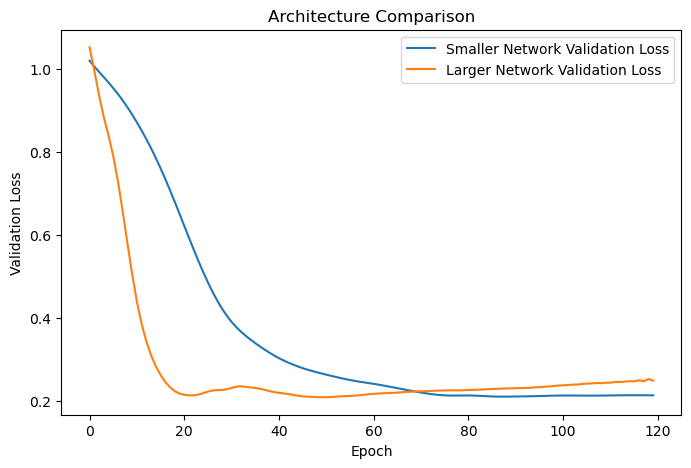

In [18]:
plt.figure(figsize=(8,5))
plt.plot(val_losses, label="Smaller Network Validation Loss")
plt.plot(large_val_loss, label="Larger Network Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Architecture Comparison")
plt.legend()
plt.show()

### Model Complexity

More neurons and layers mean more trainable parameters.

That gives the network greater capacity, but capacity is not the same as useful generalization.

The correct question is not:

> Which network is bigger?

It is:

> Which network performs reliably on data it did not train on?

## Interpretation

Ask:

- Did the larger network clearly improve validation performance?
- Did it reduce training loss more than validation loss?
- Is the additional complexity justified?

This continues the model-selection mindset from Week 7.

# 19. Final Test Evaluation

In [19]:
# The test set has remained untouched during model development.
model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_pred = torch.argmax(test_logits, dim=1).numpy()

print("Test Accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("Test Macro F1:", round(f1_score(y_test, test_pred, average="macro"), 3))

# FINAL-EVALUATION RULE:
# The test set should be used only after model-development decisions
# have been made. Repeatedly checking the test set during development
# would indirectly turn it into another validation set.


Test Accuracy: 0.919
Test Macro F1: 0.844


### Final Evaluation

The test result should be interpreted as the model's best estimate of performance on genuinely unseen data.

In the final self-driving project, this same principle becomes even more important: the vehicle should be tested on simulator conditions that were not simply memorized during development.

# 20. Connection to the Final Self-Driving Project

This week:

$$
\text{Curvature, Offset, Heading, Speed, Distance}
\rightarrow
\text{Neural Network}
\rightarrow
\text{Steering Class}
$$

Later:

$$
\text{Camera Image}
\rightarrow
\text{Deep Neural Network / CNN}
\rightarrow
\text{Steering Decision}
$$

The inputs become more sophisticated, but the learning cycle remains:

$$
\text{Input}
\rightarrow
\text{Forward Pass}
\rightarrow
\text{Prediction}
\rightarrow
\text{Loss}
\rightarrow
\text{Backpropagation}
\rightarrow
\text{Weight Update}
$$

# 21. Looking Ahead

### Week 8
Neural-network foundations using structured driving features.

### Week 9
Deep neural networks and simulator introduction.

### Week 10
Computer vision and image augmentation.

### Week 11
CNN steering prediction.

### Final Project
Integrate perception, prediction, validation, and vehicle control in simulation.

# 22. Week 8 Takeaways

- A neuron calculates a weighted sum and applies an activation function.
- Hidden layers allow the network to learn more complex representations.
- Nonlinear activation functions make neural networks more flexible than purely linear models.
- Forward propagation generates predictions.
- Loss measures prediction error.
- Backpropagation calculates gradients.
- The optimizer updates weights.
- Validation loss helps detect overfitting.
- A larger network is not automatically better.
- The same learning process will later be applied to road images.

# Reflection Questions

Use your own words and refer to the Week 8 notebook results where appropriate.

1. How is a neural network different from the linear or logistic regression models studied earlier?

2. What roles do **weights, biases, and activation functions** play in a neural network?

3. Explain the training cycle: **forward pass → prediction → loss → backpropagation → weight update**.

4. Why does decreasing training loss alone not prove that a neural network is improving?

5. In the architecture comparison, did the larger network clearly outperform the smaller network? What does this tell you about model complexity?

6. Thinking ahead to the final self-driving project, what kinds of relationships between road conditions and steering behavior might a neural network learn that would be difficult for a simple linear model?

7. Why might prediction confidence matter when a neural network is used to control an autonomous vehicle?